# EDA: Telco Customer Churn

**Mục tiêu:** hiểu dữ liệu trước khi huấn luyện, mà không để thông tin từ tập test lọt vào quyết định.

- **Dữ liệu:** IBM Telco Customer Churn, dữ liệu mẫu về một công ty hư cấu
- **Target:** `Churn` (Yes/No)
- **Nguyên tắc:** kiểm tra chất lượng trên toàn bộ dữ liệu; mọi phân tích *feature với target* chỉ dùng tập **train**

## 1. Chuẩn bị

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
CSV = ROOT / "data" / "Telco-Customer-Churn.csv"

NUMERIC = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
CATEGORICAL = ["Contract", "InternetService", "PaymentMethod"]
TARGET = "Churn"

# Màu cố định theo ý nghĩa: No = xanh, Yes = cam
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK2, "axes.edgecolor": "#c3c2b7",
    "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8, "figure.dpi": 110,
})

raw = pd.read_csv(CSV)
print(raw.shape)
raw.head(3)

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


## 2. Chất lượng dữ liệu

In [2]:
pd.DataFrame({
    "kiểu": raw.dtypes.astype(str),
    "NaN": raw.isna().sum(),
    "chuỗi trống": [(raw[c].astype(str).str.strip() == "").sum() for c in raw],
    "số giá trị": raw.nunique(),
    "ví dụ": [", ".join(map(str, raw[c].unique()[:4])) for c in raw],
})

,kiểu,NaN,chuỗi trống,số giá trị,ví dụ
customerID,str,0,0,7043,"7590-VHVEG, 5575-GNVDE, 3668-QPYBK, 7795-CFOCW"
gender,str,0,0,2,"Female, Male"
SeniorCitizen,int64,0,0,2,"0, 1"
Partner,str,0,0,2,"Yes, No"
Dependents,str,0,0,2,"No, Yes"
tenure,int64,0,0,73,"1, 34, 2, 45"
PhoneService,str,0,0,2,"No, Yes"
MultipleLines,str,0,0,3,"No phone service, No, Yes"
InternetService,str,0,0,3,"DSL, Fiber optic, No"
OnlineSecurity,str,0,0,3,"No, Yes, No internet service"


In [3]:
blank = raw["TotalCharges"].str.strip() == ""
print("customerID trùng:", raw["customerID"].duplicated().sum())
print("Dòng giống nhau khi bỏ customerID:", raw.drop(columns="customerID").duplicated().sum())
print("TotalCharges trống:", blank.sum(), "| tenure = 0:", (raw["tenure"] == 0).sum())
raw.loc[blank].value_counts(["tenure", "Churn"])

customerID trùng: 0
Dòng giống nhau khi bỏ customerID: 22
TotalCharges trống: 11 | tenure = 0: 11


tenure  Churn
0       No       11
Name: count, dtype: int64

`isna()` báo **0** giá trị thiếu, nhưng `TotalCharges` có 11 ô chỉ chứa dấu cách, nên pandas đọc cả cột thành chữ.

Cả 11 khách này có `tenure = 0`, nhiều khả năng chưa trả kỳ nào. Điền **0** là hợp lý. Đây là hằng số, không học từ dữ liệu, nên không gây leakage.

In [4]:
def clean(d):
    """Làm sạch theo quy tắc cố định, không học gì từ dữ liệu."""
    d = d.copy()
    d["TotalCharges"] = pd.to_numeric(d["TotalCharges"], errors="coerce").fillna(0.0)
    return d.drop(columns="customerID")

df = clean(raw)
assert df.notna().all().all()
assert (df[["tenure", "MonthlyCharges", "TotalCharges"]] >= 0).all().all()
assert set(df[TARGET]) == {"Yes", "No"}
df[NUMERIC].describe().round(2)

,tenure,MonthlyCharges,TotalCharges,SeniorCitizen
count,7043.00,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73,0.16
std,24.56,30.09,2266.79,0.37
min,0.00,18.25,0.00,0.00
25%,9.00,35.50,398.55,0.00
50%,29.00,70.35,1394.55,0.00
75%,55.00,89.85,3786.60,0.00
max,72.00,118.75,8684.80,1.00


Không có giá trị âm hay ngoài khoảng hợp lý. Thang đo lệch nhau nhiều (`tenure` tới 72, `TotalCharges` tới hơn 8600), nên cần **scale** trước Logistic Regression.

## 3. Target và baseline

In [5]:
rate = (df[TARGET] == "Yes").mean()
print(f"Churn: {rate:.1%}  |  Yes {(df[TARGET] == 'Yes').sum()}  /  No {(df[TARGET] == 'No').sum()}")
print(f"Luôn đoán No: accuracy = {1 - rate:.1%}, recall của churn = 0%")

Churn: 26.5%  |  Yes 1869  /  No 5174
Luôn đoán No: accuracy = 73.5%, recall của churn = 0%


Dữ liệu **mất cân bằng** khoảng 1:3. Accuracy quanh 73.5% không chứng tỏ model học được gì, nên cần thêm F1, ROC-AUC và PR-AUC.

## 4. Tách train/test

Từ đây tập test được **cất đi**. Nếu `train.py` dùng cùng file, cùng thứ tự dòng, `test_size`, `random_state` và `stratify` thì tập test sẽ giống hệt.

In [6]:
train, test = train_test_split(df, test_size=0.2, random_state=RANDOM_STATE, stratify=df[TARGET])
train = train.assign(y=(train[TARGET] == "Yes").astype(int))
print(f"train {len(train)} dòng, churn {train['y'].mean():.2%}")
print(f"test  {len(test)} dòng, churn {(test[TARGET] == 'Yes').mean():.2%}")
del test  # EDA không dùng tới
BASE = train["y"].mean()

def churn_table(d, by):
    """Số khách, tỷ lệ churn và khoảng tin cậy Wilson 95%."""
    t = d.groupby(by, observed=True)["y"].agg(n="size", rate="mean")
    z = 1.96
    den = 1 + z**2 / t.n
    mid = (t.rate + z**2 / (2 * t.n)) / den
    half = z * np.sqrt(t.rate * (1 - t.rate) / t.n + z**2 / (4 * t.n**2)) / den
    return t.assign(lo=mid - half, hi=mid + half)

train 5634 dòng, churn 26.54%
test  1409 dòng, churn 26.54%


## 5. Feature số

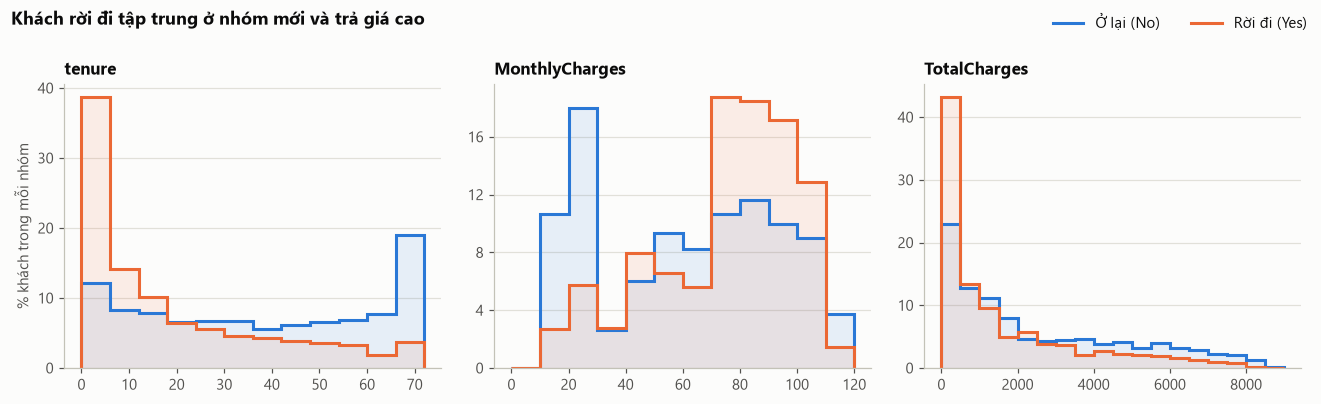

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.40,1686.15
Yes,10.0,79.95,740.30


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.7))
for ax, col, step in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"], [6, 10, 500]):
    bins = np.arange(0, train[col].max() + step, step)
    for label, color in [("No", BLUE), ("Yes", ORANGE)]:
        v = train.loc[train[TARGET] == label, col]
        w = np.full(len(v), 100 / len(v))
        ax.hist(v, bins=bins, weights=w, histtype="stepfilled", color=color, alpha=0.10)
        ax.hist(v, bins=bins, weights=w, histtype="step", color=color, lw=2)
    ax.set_title(col)
    ax.grid(axis="y")
    ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True, nbins=5))
axes[0].set_ylabel("% khách trong mỗi nhóm")
handles = [plt.Line2D([], [], color=c, lw=2) for c in (BLUE, ORANGE)]
fig.legend(handles, ["Ở lại (No)", "Rời đi (Yes)"], loc="upper right", ncol=2, frameon=False)
fig.suptitle("Khách rời đi tập trung ở nhóm mới và trả giá cao", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.98))
plt.show()
train.groupby(TARGET)[["tenure", "MonthlyCharges", "TotalCharges"]].median()

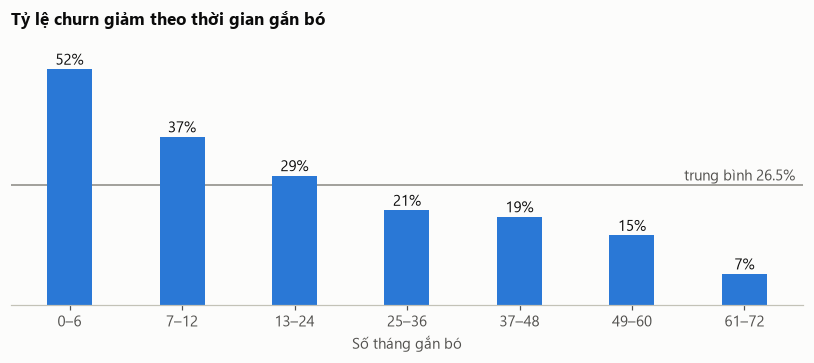

,n,rate,lo,hi
tenure_bin,,,,
0–6,1170,0.522,0.494,0.551
7–12,567,0.372,0.333,0.413
13–24,818,0.286,0.256,0.318
25–36,669,0.209,0.180,0.242
37–48,621,0.195,0.166,0.228
49–60,658,0.153,0.128,0.183
61–72,1131,0.068,0.055,0.084


In [8]:
train["tenure_bin"] = pd.cut(train["tenure"], [-1, 6, 12, 24, 36, 48, 60, 72],
                             labels=["0–6", "7–12", "13–24", "25–36", "37–48", "49–60", "61–72"])
t = churn_table(train, "tenure_bin")
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.bar(t.index.astype(str), t.rate * 100, width=0.4, color=BLUE)
for i, r in enumerate(t.rate):
    ax.text(i, r * 100 + 1, f"{r:.0%}", ha="center")
ax.axhline(BASE * 100, color=MUTED, lw=1, zorder=0)
ax.text(6.45, BASE * 100 + 1, f"trung bình {BASE:.1%}", ha="right", color=INK2)
ax.set(xlabel="Số tháng gắn bó", yticks=[], ylim=(0, 60))
ax.spines["left"].set_visible(False)
ax.set_title("Tỷ lệ churn giảm theo thời gian gắn bó")
fig.tight_layout()
plt.show()
t.round(3)

## 6. Feature danh mục

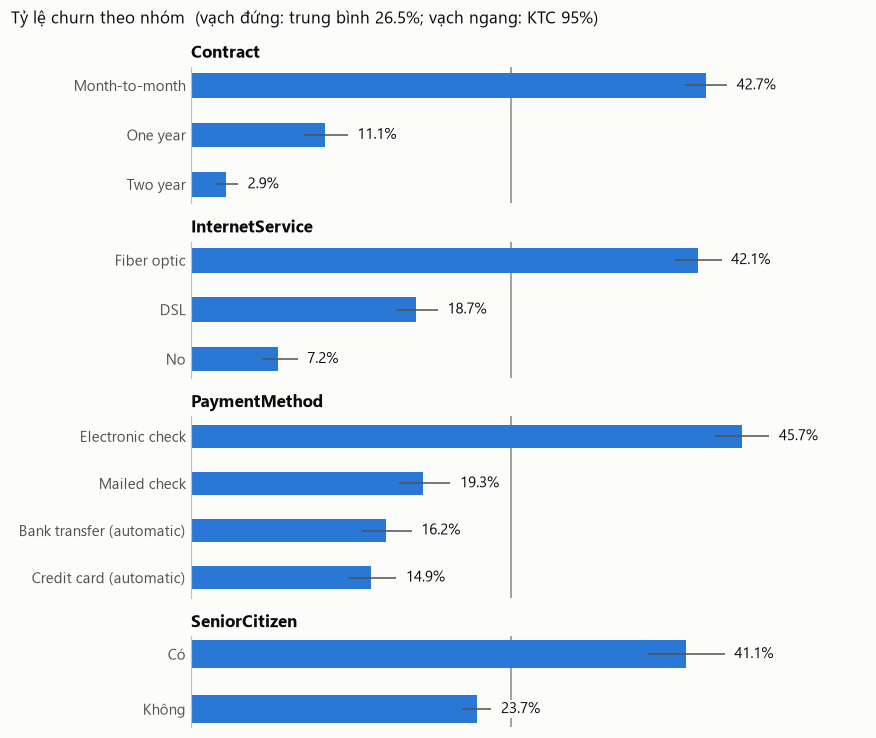

n   rate     lo     hi
Contract        Two year                   1359  0.029  0.021  0.039
                One year                   1173  0.111  0.094  0.130
                Month-to-month             3102  0.427  0.410  0.445
InternetService No                         1214  0.072  0.059  0.088
                DSL                        1937  0.187  0.170  0.205
                Fiber optic                2483  0.421  0.402  0.440
PaymentMethod   Credit card (automatic)    1213  0.149  0.130  0.170
                Bank transfer (automatic)  1244  0.162  0.142  0.183
                Mailed check               1286  0.193  0.172  0.215
                Electronic check           1891  0.457  0.435  0.480
SeniorCitizen   0                          4714  0.237  0.225  0.249
                1                           920  0.411  0.380  0.443

In [9]:
cols = CATEGORICAL + ["SeniorCitizen"]
tabs = [churn_table(train, c).sort_values("rate") for c in cols]
fig, axes = plt.subplots(4, 1, figsize=(8, 6.8), sharex=True,
                         gridspec_kw={"height_ratios": [len(t) for t in tabs]})
for ax, c, t in zip(axes, cols, tabs):
    names = [{"0": "Không", "1": "Có"}.get(str(i), str(i)) for i in t.index]
    ax.barh(names, t.rate * 100, height=0.5, color=BLUE)
    ax.errorbar(t.rate * 100, names, xerr=[(t.rate - t.lo) * 100, (t.hi - t.rate) * 100],
                fmt="none", ecolor=INK2, elinewidth=1)
    for i, (r, hi) in enumerate(zip(t.rate, t.hi)):
        ax.text(hi * 100 + 0.8, i, f"{r:.1%}", va="center",
                bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1))
    ax.axvline(BASE * 100, color=MUTED, lw=1, zorder=0)
    ax.set_title(c)
    ax.spines["bottom"].set_visible(False)
    ax.tick_params(length=0)
axes[-1].set_xticks([])
axes[0].set_xlim(0, 56)
fig.suptitle(f"Tỷ lệ churn theo nhóm  (vạch đứng: trung bình {BASE:.1%}; vạch ngang: KTC 95%)",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()
pd.concat(dict(zip(cols, tabs))).round(3)

## 7. Nhìn một cột là chưa đủ: yếu tố gây nhiễu

### 7.1. Contract × InternetService

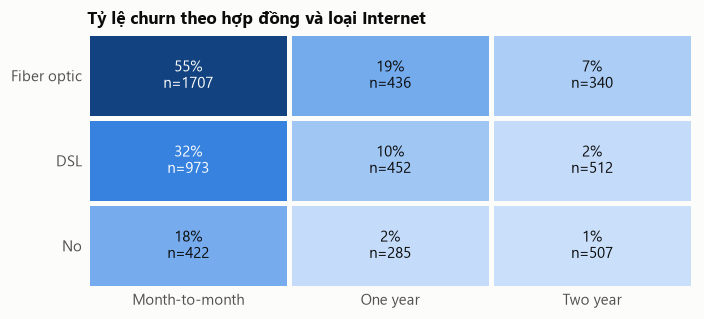

In [10]:
BLUES = LinearSegmentedColormap.from_list("b", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
g = train.pivot_table(index="InternetService", columns="Contract", values="y", aggfunc=["mean", "size"])
order = ["Fiber optic", "DSL", "No"]
p, n = g["mean"].loc[order], g["size"].loc[order]
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.pcolormesh(p.values * 100, cmap=BLUES, vmin=0, vmax=60, edgecolors=SURFACE, linewidth=2)
for i in range(3):
    for j in range(3):
        v = p.values[i, j]
        ax.text(j + .5, i + .5, f"{v:.0%}\nn={n.values[i, j]}", ha="center", va="center",
                color="white" if v > .25 else INK)
ax.set(xticks=np.arange(3) + .5, yticks=np.arange(3) + .5)
ax.set_xticklabels(p.columns)
ax.set_yticklabels(p.index)
ax.invert_yaxis()
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("Tỷ lệ churn theo hợp đồng và loại Internet")
fig.tight_layout()
plt.show()

### 7.2. MonthlyCharges: xu hướng đảo chiều

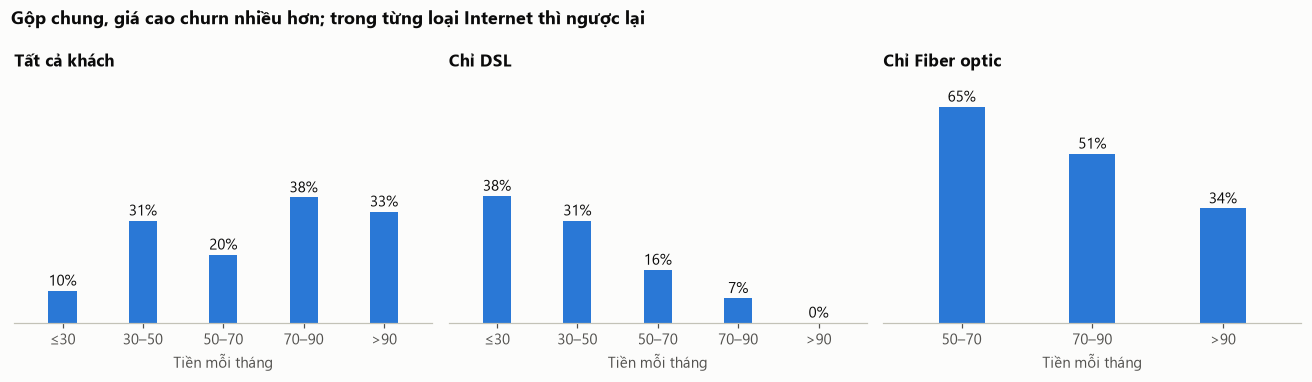

n   rate     lo     hi
InternetService charge_bin                           
DSL             ≤30          100  0.380  0.291  0.478
                30–50        523  0.306  0.268  0.347
                50–70        827  0.158  0.135  0.185
                70–90        448  0.074  0.053  0.102
                >90           39  0.000  0.000  0.090
Fiber optic     50–70         85  0.647  0.541  0.740
                70–90       1031  0.506  0.476  0.537
                >90         1367  0.342  0.318  0.368
No              ≤30         1214  0.072  0.059  0.088

In [11]:
train["charge_bin"] = pd.cut(train["MonthlyCharges"], [0, 30, 50, 70, 90, 120],
                             labels=["≤30", "30–50", "50–70", "70–90", ">90"])
allc = churn_table(train, "charge_bin")
sub = churn_table(train, ["InternetService", "charge_bin"])
panels = [("Tất cả khách", allc), ("Chỉ DSL", sub.loc["DSL"]), ("Chỉ Fiber optic", sub.loc["Fiber optic"])]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for ax, (name, t) in zip(axes, panels):
    t = t[t.n >= 30]  # bỏ nhóm quá ít khách
    ax.bar(t.index.astype(str), t.rate * 100, width=0.35, color=BLUE)
    for i, r in enumerate(t.rate):
        ax.text(i, r * 100 + 1.5, f"{r:.0%}", ha="center")
    ax.set_title(name)
    ax.set_xlabel("Tiền mỗi tháng")
    ax.set_xlim(-0.6, len(t) - 0.4)
    ax.set_ylim(0, 74)
    ax.set_yticks([])
    ax.spines["left"].set_visible(False)
fig.suptitle("Gộp chung, giá cao churn nhiều hơn; trong từng loại Internet thì ngược lại", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()
sub.round(3)

In [12]:
# Chênh lệch có còn khi giữ cố định loại Internet, hợp đồng VÀ thời gian gắn bó?
s = train[(train["InternetService"] != "No") & (train["Contract"] == "Month-to-month")].copy()
s["tenure_grp"] = pd.cut(s["tenure"], [-1, 12, 72], labels=["≤12 tháng", ">12 tháng"])
med = s.groupby("InternetService")["MonthlyCharges"].transform("median")
s["giá"] = np.where(s["MonthlyCharges"] > med, "trên trung vị", "từ trung vị trở xuống")
churn_table(s, ["InternetService", "tenure_grp", "giá"]).round(3)

n   rate     lo     hi
InternetService tenure_grp giá                                            
DSL             ≤12 tháng  trên trung vị          227  0.330  0.272  0.394
                           từ trung vị trở xuống  327  0.468  0.414  0.522
                >12 tháng  trên trung vị          256  0.168  0.127  0.219
                           từ trung vị trở xuống  163  0.233  0.175  0.304
Fiber optic     ≤12 tháng  trên trung vị          228  0.781  0.723  0.830
                           từ trung vị trở xuống  502  0.681  0.639  0.721
                >12 tháng  trên trung vị          622  0.437  0.399  0.477
                           từ trung vị trở xuống  355  0.417  0.367  0.469

### 7.3. Electronic check và tenure, xét riêng từng loại hợp đồng

In [13]:
train["e_check"] = np.where(train["PaymentMethod"] == "Electronic check", "Electronic check", "Cách khác")
display(churn_table(train, ["Contract", "e_check"]).round(3))
display(churn_table(train, ["Contract", "tenure_bin"])[["n", "rate"]].unstack(0).round(3))

n   rate     lo     hi
Contract       e_check                                    
Month-to-month Cách khác         1618  0.322  0.300  0.345
               Electronic check  1484  0.542  0.517  0.568
One year       Cách khác          895  0.089  0.072  0.110
               Electronic check   278  0.180  0.139  0.229
Two year       Cách khác         1230  0.024  0.016  0.034
               Electronic check   129  0.078  0.043  0.137

n                             rate                  
Contract   Month-to-month One year Two year Month-to-month One year Two year
tenure_bin                                                                  
0–6                  1122       23       25          0.544    0.043    0.000
7–12                  472       65       30          0.432    0.108    0.000
13–24                 580      166       72          0.383    0.072    0.000
25–36                 396      191       82          0.311    0.079    0.024
37–48                 254      222      145          0.354    0.131    0.014
49–60                 190      253      215          0.295    0.142    0.042
61–72                  88      253      790          0.239    0.119    0.033

## 8. Feature trùng lặp thông tin

In [14]:
X = train[NUMERIC].astype(float)
corr = np.corrcoef(X["TotalCharges"], X["tenure"] * X["MonthlyCharges"])[0, 1]
print(f"corr(TotalCharges, tenure × MonthlyCharges) = {corr:.4f}")

def vif(d):
    return pd.Series(np.diag(np.linalg.inv(d.corr().values)), index=d.columns).round(2)

display(pd.DataFrame({"VIF (4 cột)": vif(X), "VIF (bỏ TotalCharges)": vif(X.drop(columns="TotalCharges"))}))
X.assign(churn=train["y"]).corr().round(2)

corr(TotalCharges, tenure × MonthlyCharges) = 0.9996


,VIF (4 cột),VIF (bỏ TotalCharges)
MonthlyCharges,3.32,1.13
SeniorCitizen,1.05,1.05
TotalCharges,9.70,NaN
tenure,5.93,1.07


,tenure,MonthlyCharges,TotalCharges,SeniorCitizen,churn
tenure,1.00,0.26,0.83,0.02,-0.35
MonthlyCharges,0.26,1.00,0.65,0.22,0.20
TotalCharges,0.83,0.65,1.00,0.10,-0.19
SeniorCitizen,0.02,0.22,0.10,1.00,0.15
churn,-0.35,0.20,-0.19,0.15,1.00


## 9. Các cột ngoài phạm vi bài học

Bài học dùng 7 feature. Cramér's V (0 = không liên hệ, 1 = hoàn toàn) gợi ý cột nào đáng thử thêm.

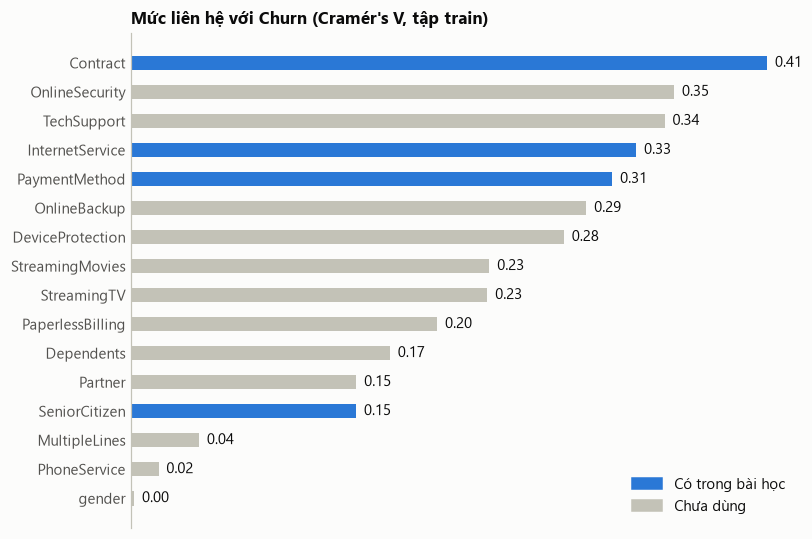

In [15]:
def cramers_v(x, y):
    o = pd.crosstab(x, y).to_numpy(dtype=float)
    e = o.sum(1, keepdims=True) * o.sum(0, keepdims=True) / o.sum()
    return np.sqrt(((o - e) ** 2 / e).sum() / o.sum() / (min(o.shape) - 1))

cats = [c for c in df.columns if c not in ["tenure", "MonthlyCharges", "TotalCharges", TARGET]]
v = pd.Series({c: cramers_v(train[c], train["y"]) for c in cats}).sort_values()
in_scope = v.index.isin(CATEGORICAL + ["SeniorCitizen"])
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.barh(list(v.index), v, height=0.5, color=np.where(in_scope, BLUE, "#c3c2b7"))
for i, x in enumerate(v):
    ax.text(x + 0.005, i, f"{x:.2f}", va="center")
ax.set_xticks([])
ax.spines["bottom"].set_visible(False)
ax.tick_params(length=0)
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in (BLUE, "#c3c2b7")],
          ["Có trong bài học", "Chưa dùng"], frameon=False, loc="lower right")
ax.set_title("Mức liên hệ với Churn (Cramér's V, tập train)")
fig.tight_layout()
plt.show()

Các cột dịch vụ kèm có giá trị `No internet service`, trùng thông tin với `InternetService = No`, nên V ở trên bị thổi lên. Tính lại **chỉ trên khách có Internet**:

In [16]:
addons = ["OnlineSecurity", "TechSupport", "OnlineBackup", "DeviceProtection", "StreamingTV", "StreamingMovies"]
net = train[train["InternetService"] != "No"]
pd.DataFrame({
    "V (tất cả)": v[addons],
    "V (có Internet)": {c: cramers_v(net[c], net["y"]) for c in addons},
    "churn khi No": {c: net.loc[net[c] == "No", "y"].mean() for c in addons},
    "churn khi Yes": {c: net.loc[net[c] == "Yes", "y"].mean() for c in addons},
}).round(3)

,V (tất cả),V (có Internet),churn khi No,churn khi Yes
OnlineSecurity,0.351,0.285,0.419,0.144
TechSupport,0.345,0.276,0.418,0.152
OnlineBackup,0.294,0.198,0.401,0.216
DeviceProtection,0.280,0.172,0.390,0.228
StreamingTV,0.230,0.028,0.331,0.305
StreamingMovies,0.232,0.038,0.336,0.300


## 10. Kết luận

Các số về feature dưới đây đều tính trên tập train.

### Phát hiện chính

1. **`Contract` là tín hiệu mạnh nhất trong các cột danh mục** (V = 0.41): Month-to-month 42.7%, One year 11.1%, Two year 2.9%.
2. **6 tháng đầu nguy hiểm nhất:** churn 52%, so với 7% ở nhóm 61–72 tháng. Xu hướng giảm này chủ yếu đến từ khách Month-to-month; ở hợp đồng One year và Two year, churn không giảm theo tenure.
3. **Nhóm rủi ro cao nhất (Contract × Internet):** Fiber optic + Month-to-month, churn 55%, gồm 1707 khách (30% tập train).
4. **`Electronic check` churn cao hơn trong cả ba loại hợp đồng** (ví dụ 54% so với 32% ở Month-to-month), nên không chỉ là hệ quả của loại hợp đồng.
5. **`MonthlyCharges` không có một chiều ảnh hưởng duy nhất:**
   - Gộp chung thì giá cao churn nhiều hơn (tương quan +0.20).
   - Trong riêng DSL hoặc riêng Fiber thì ngược lại.
   - Khi giữ thêm Month-to-month và tenure: DSL giá cao vẫn churn ít hơn ở khách mới; Fiber giá cao lại churn **nhiều hơn** ở khách mới (78% so với 68%) và gần như không khác ở khách trên 12 tháng.
6. **`TotalCharges` gần như thừa:** tương quan 0.9996 với `tenure × MonthlyCharges`; bỏ nó thì VIF của `tenure` giảm từ 5.9 xuống 1.1.
7. **Cột ngoài bài học đáng thử:** `OnlineSecurity`, `TechSupport`. `StreamingTV` và `StreamingMovies` có V khoảng 0.23, nhưng chỉ còn 0.03–0.04 khi xét riêng khách có Internet.

### Việc cần làm khi huấn luyện

| Việc | Lý do |
|---|---|
| `clean()`: ép kiểu và điền 0 cho `TotalCharges` | 11 ô chỉ chứa dấu cách |
| `StandardScaler` + `OneHotEncoder` trong `Pipeline` | Chỉ fit trên train, chống leakage |
| So sánh có và không có `TotalCharges` **bằng cross-validation trên train** | Đa cộng tuyến; không dùng test để chọn |
| Thử tương tác `InternetService × MonthlyCharges` | Phát hiện 5 |
| Báo cáo F1, ROC-AUC, PR-AUC cạnh accuracy | Baseline accuracy đã là 73.5% |

### Giới hạn

- **Không có mốc thời gian:** dữ liệu là một lát cắt, nên không kiểm tra được temporal leakage và không biết churn xảy ra trong bao lâu.
- **Tương quan, không phải nhân quả:** bắt khách đổi cách thanh toán chưa chắc giữ được họ.
- **Dữ liệu hư cấu:** kết luận không áp dụng thẳng cho nhà mạng thật.
- **Tập test không hoàn toàn "chưa nhìn":** khi kiểm tra file tải về, tỷ lệ churn theo nhóm của `Contract`, `InternetService`, `PaymentMethod` và `SeniorCitizen` đã được xem trên toàn bộ dữ liệu. Danh sách feature do bài học định sẵn nên ảnh hưởng không đáng kể.